# 2. Two-site population dynamics

**Question:** which occupations exchange population, and what determines the
oscillation amplitude and period? Source: thesis Sec. 3.8 and Fig. 3;
original `heff2_states.py`. This notebook treats a closed nine-state model.

## Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

## 2.1 Basis, channels, and the three-state block

Use the ordered basis
$$\{|00\rangle,|01\rangle,|02\rangle,|10\rangle,|11\rangle,
    |12\rangle,|20\rangle,|21\rangle,|22\rangle\}.$$
The $N=1$ block is $\{|01\rangle,|10\rangle\}$, the $N=2$ block is
$\{|02\rangle,|11\rangle,|20\rangle\}$, and the $N=3$ block is
$\{|12\rangle,|21\rangle\}$. The $N=0$ and $N=4$ blocks have one state each.
Consequently $|11\rangle$ generally couples to **two** states at once.
A two-state Rabi formula is not its general solution.

The two-site laser-phase assignment retained from the source is
$$\boldsymbol\vartheta=(-\alpha,\ \beta-2\alpha,\ \alpha-2\beta,\ -\beta).$$
This is a definition of the numerical bond model here, not a claim about
implementing a uniform phase pattern on every bond of a longer chain.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd().resolve()
roots = [p for p in (here, *here.parents) if (p / 'anyon_thesis').is_dir()]
if not roots:
    raise FileNotFoundError('Open this notebook from the cloned repository.')
ROOT = roots[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from anyon_thesis.models import (
    EffectiveParameters, effective_bond, effective_chain, occupation_basis,
    phase_pattern, basis_state, evolve_probabilities, parameter_curves,
    target_hamiltonian, lowest_levels, gap_grid,
)
SAVE_FIGURES = False  # Optional export; raw scripts/data are never overwritten.
STYLE = {'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}
def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / 'notebook_outputs'
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f'{name}.png', dpi=160)
    display(fig)
    plt.close(fig)
np.set_printoptions(precision=6, suppress=True)

In [2]:
p = EffectiveParameters()
diagonal, rates, info = effective_bond(p)
phases = phase_pattern('laser_pair', alpha=np.pi/4, beta=np.pi/3)
H, basis = effective_chain(2, diagonal, rates, phases)
labels = [''.join(map(str, cfg)) for cfg in basis]
print('Basis:', labels)
print('Signed rates:', rates)
print('Imposed |11> diagonal shift:', info['imposed_11_shift'])
print('N=2 block:\n', H[np.ix_([2, 4, 6], [2, 4, 6])])
assert np.allclose(H, H.conj().T)

Basis: ['00', '01', '02', '10', '11', '12', '20', '21', '22']
Signed rates: [-0.05     0.01661  0.01661 -0.01012]
Imposed |11> diagonal shift: -0.2702366491755135
N=2 block:
 [[-0.060117+0.j        0.004299+0.016044j  0.      +0.j      ]
 [ 0.004299-0.016044j -0.060117+0.j        0.014384+0.008305j]
 [ 0.      +0.j        0.014384-0.008305j -0.060117+0.j      ]]


## 2.2 Derive the propagator before evaluating it

Let the orthonormal eigenvectors satisfy $Kv_m=\lambda_m v_m$. Form the
unitary matrix $V=(v_0,v_1,\ldots)$ so that $V^\dagger V=I$ and
$K=V\Lambda V^\dagger$. Expand the normalized initial state:
$$c_m=v_m^\dagger\psi(0),\qquad
  \psi(0)=\sum_m c_m v_m.$$
Inserting this into $i\,d\psi/d\tau=K\psi$ gives an equation for each
coefficient: $i\,dc_m(\tau)/d\tau=\lambda_m c_m(\tau)$.
Its solution with boundary value $c_m(0)=c_m$ is
$$c_m(\tau)=e^{-i\lambda_m\tau}c_m,\qquad
  \psi(\tau)=\sum_m e^{-i\lambda_m\tau}v_m v_m^\dagger\psi(0).$$
Every exponent is dimensionless. Projection onto basis state $s$ gives
$$P_s(\tau)=|\langle s|\psi(\tau)\rangle|^2.$$
Since $|e^{-i\lambda_m\tau}|=1$ for real $\lambda_m$,
$\sum_sP_s=\sum_m|c_m|^2=1$. There is no loss or decoherence term in this model.

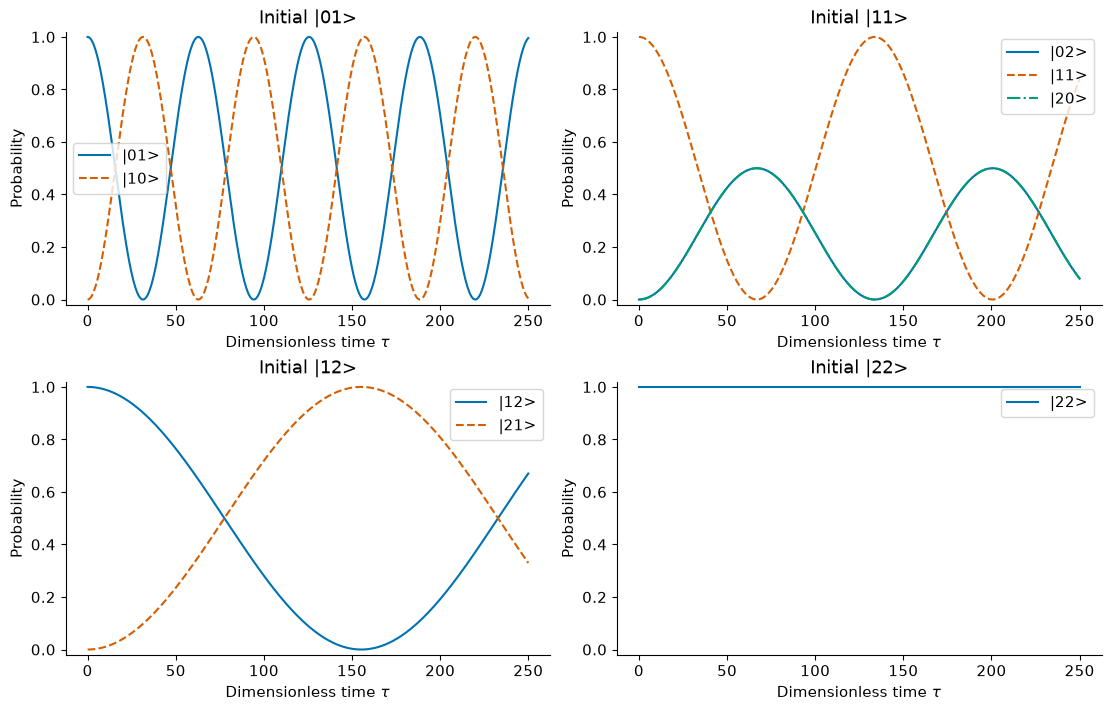

All displayed probability sums equal one within numerical tolerance.


In [3]:
tau = np.linspace(0, 250, 501)
initial_occupations = [(0, 1), (1, 1), (1, 2), (2, 2)]
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
    for ax, initial in zip(axes.flat, initial_occupations):
        psi0 = basis_state(basis, initial)
        probabilities = evolve_probabilities(H, psi0, tau)
        assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-12)
        visible = np.flatnonzero(probabilities.max(axis=0) > 1e-10)
        for index, colour, style in zip(visible, ['#0072B2', '#D55E00', '#009E73'],
                                        ['-', '--', '-.']):
            ax.plot(tau, probabilities[:, index], color=colour, linestyle=style,
                    label=f'|{labels[index]}>')
        ax.set(xlabel=r'Dimensionless time $\tau$', ylabel='Probability',
               ylim=(-0.02, 1.02), title=f'Initial |{initial[0]}{initial[1]}>')
        ax.legend()
    show_figure(fig, '02_bond_probabilities')
print('All displayed probability sums equal one within numerical tolerance.')

**Figure description:** each panel starts in its labelled occupation state;
line styles and legends identify the populated basis states. The $|11\rangle$
panel contains both $|02\rangle$ and $|20\rangle$. The $|22\rangle$ state
remains dark in the truncated exchange model.

## 2.3 A two-state solution for the isolated exchange blocks

For two states $a,b$, subtract the common diagonal energy
$\bar\epsilon=(\epsilon_a+\epsilon_b)/2$. This produces only a global phase.
Set $\delta=(\epsilon_a-\epsilon_b)/2$ and write
$$K'=\begin{pmatrix}\delta&g^*\\g&-\delta\end{pmatrix}.$$
Multiplication gives
$$K'^2=\begin{pmatrix}\delta^2+|g|^2&\delta g^*-g^*\delta\\
  g\delta-\delta g&|g|^2+\delta^2\end{pmatrix}
  =(\delta^2+|g|^2)I.$$
Put $q=\sqrt{\delta^2+|g|^2}$. Separate even and odd powers of the exponential:
$$e^{-iK'\tau}=I\cos(q\tau)-i\frac{K'}q\sin(q\tau).$$
The off-diagonal transition amplitude from $a$ to $b$ is
$-ig\sin(q\tau)/q$, so
$$P_{a\to b}(\tau)=\frac{|g|^2}{|g|^2+\delta^2}
   \sin^2\!\left(\sqrt{|g|^2+\delta^2}\,\tau\right).$$
On resonance ($\delta=0$), the transfer can reach one. For $|g|\to0$ at fixed
nonzero $\delta$, its amplitude tends to zero. If both vanish, $K'=0$ and the
state is stationary; use this limit instead of dividing by zero.

In [4]:
ia, ib = labels.index('01'), labels.index('10')
psi0 = basis_state(basis, (0, 1))
numerical = evolve_probabilities(H, psi0, tau)[:, ib]
delta = (H[ia, ia].real - H[ib, ib].real)/2
g = H[ib, ia]
q = np.sqrt(abs(g)**2+delta**2)
analytic = abs(g)**2/q**2*np.sin(q*tau)**2 if q > 0 else np.zeros_like(tau)
error = np.max(abs(numerical-analytic))
print('Two-level analytic/numerical discrepancy:', error)
assert error < 1e-12
assert np.allclose(evolve_probabilities(H, psi0, [0])[0], abs(psi0)**2)

Two-level analytic/numerical discrepancy: 1.6653345369377348e-15


## 2.4 Resonant three-state check

If the three diagonals are equal, $|11\rangle$ couples to a normalized bright
combination of the two outer states, with total strength
$G=\sqrt{|g_2|^2+|g_3|^2}$. The orthogonal outer-state combination is dark.
For explicit phases, define the two center-to-outer matrix elements
$t_{20}=g_2e^{i\vartheta_2}$ and $t_{02}=g_3e^{-i\vartheta_3}$.
After subtracting the equal diagonal, the three-state matrix is
$$K'=t_{20}|20\rangle\langle11|+t_{02}|02\rangle\langle11|+\mathrm{h.c.}$$
For $G>0$, the bright and dark states are
$$|B\rangle=\frac{t_{20}|20\rangle+t_{02}|02\rangle}{G},\qquad
  |D\rangle=\frac{t_{02}^*|20\rangle-t_{20}^*|02\rangle}{G}.$$
Their overlap is
$$\langle B|D\rangle=
  \frac{t_{20}^*t_{02}^*-t_{02}^*t_{20}^*}{G^2}=0.$$
Direct application gives $K'|11\rangle=G|B\rangle$,
$K'|B\rangle=G|11\rangle$, and $K'|D\rangle=0$.
The active two-state block is consequently
$\begin{pmatrix}0&G\\G&0\end{pmatrix}$ in the basis
$(|11\rangle,|B\rangle)$. The preceding two-state derivation gives
$$|\psi(\tau)\rangle=\cos(G\tau)|11\rangle-i\sin(G\tau)|B\rangle.$$
For $G=0$, the initial state is stationary and $B,D$ need not be defined.
Starting in $|11\rangle$ therefore gives
$$P_{11}(\tau)=\cos^2(G\tau),\quad
  P_{20}(\tau)=\frac{|g_2|^2}{G^2}\sin^2(G\tau),\quad
  P_{02}(\tau)=\frac{|g_3|^2}{G^2}\sin^2(G\tau).$$
The two outer probabilities add to $\sin^2(G\tau)$, so normalization is
explicit. For equal magnitudes, each outer state can receive at most one half
from this initial state. This statement assumes exact equal diagonals and
no extra couplings; it is not the detuned three-state solution.

In [5]:
P = evolve_probabilities(H, basis_state(basis, (1, 1)), tau)
G = np.hypot(abs(rates[1]), abs(rates[2]))
assert np.allclose(P[:, labels.index('11')], np.cos(G*tau)**2, atol=1e-12)
assert np.allclose(P[:, labels.index('20')], abs(rates[1])**2/G**2*np.sin(G*tau)**2)
assert np.allclose(P[:, labels.index('02')], abs(rates[2])**2/G**2*np.sin(G*tau)**2)
print('Resonant bright/dark-state probability identities: PASS')

Resonant bright/dark-state probability identities: PASS


## Sources and limits of this notebook

- Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de
  Barcelona, 2026: [institutional record](https://hdl.handle.net/2445/231684).
  See the relevant sections and equations identified above.
- [Archived thesis and code deposit](https://doi.org/10.5281/zenodo.23443035).
- Original scripts in [`scripts/`](../scripts/) at source commit
  `22959963191fcbc4d283ec4b272b506ad6dd979b`; this notebook is a new explanatory
  implementation. The original script and data bytes are preserved.
- [SciPy `eigsh` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html)
  for the sparse eigenvalue solver. For complex Hermitian input, SciPy uses
  its complex eigensolver internally; residual checks remain necessary.

These finite-size calculations do not independently validate the microscopic
derivation, establish an experimental realization, or prove a thermodynamic
phase transition. No new empirical evidence is introduced.